In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ttest_ind, chi2_contingency, f_oneway
from statsmodels.stats.multicomp import pairwise_tukeyhsd

In [2]:
df = pd.read_csv("Housing.csv")
print("Dataset shape:", df.shape)

Dataset shape: (545, 13)


In [3]:
alpha = 0.05
num_col, group_col = "price", "mainroad"
group_a, group_b = "yes", "no"
cat_col1, cat_col2 = "mainroad", "airconditioning"
anova_num_col, anova_group_col = "price", "bedrooms"

def decide(p):
    return "Reject H0" if p < alpha else "Fail to reject H0"

print(df[group_col].value_counts())
print(df[anova_group_col].value_counts())

mainroad
yes    468
no      77
Name: count, dtype: int64
bedrooms
3    300
2    136
4     95
5     10
6      2
1      2
Name: count, dtype: int64


yes count: 468, mean: 4991777.33, std: 1893639.11
no count: 77, mean: 3398904.55, std: 894735.46


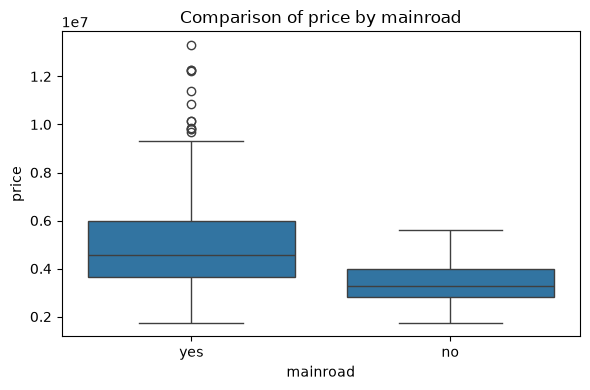

Welch's t-test: Statistic = 11.8532, p-value = 3.6327e-25 -> Reject H0


In [4]:
g1 = df.loc[df[group_col] == group_a, num_col].dropna()
g2 = df.loc[df[group_col] == group_b, num_col].dropna()
print(f"{group_a} count: {len(g1)}, mean: {g1.mean():.2f}, std: {g1.std():.2f}")
print(f"{group_b} count: {len(g2)}, mean: {g2.mean():.2f}, std: {g2.std():.2f}")

plt.figure(figsize=(6, 4))
sns.boxplot(data=df[df[group_col].isin([group_a, group_b])], x=group_col, y=num_col)
plt.title(f"Comparison of {num_col} by {group_col}")
plt.tight_layout()
plt.show()

t_stat, t_p = ttest_ind(g1, g2, equal_var=False)
print(f"Welch's t-test: Statistic = {t_stat:.4f}, p-value = {t_p:.4e} -> {decide(t_p)}")

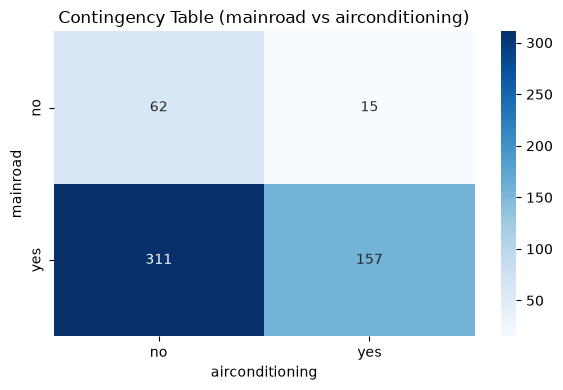

Chi-square test: Statistic = 5.4234, dof = 1, p-value = 1.9869e-02 -> Reject H0
Expected Frequencies:
 airconditioning     no    yes
mainroad                     
no                52.7   24.3
yes              320.3  147.7


In [5]:
chi_df = df[[cat_col1, cat_col2]].dropna()
observed = pd.crosstab(chi_df[cat_col1], chi_df[cat_col2])

plt.figure(figsize=(6, 4))
sns.heatmap(observed, annot=True, fmt="d", cmap="Blues")
plt.title(f"Contingency Table ({cat_col1} vs {cat_col2})")
plt.tight_layout()
plt.show()

chi2, chi_p, dof, expected = chi2_contingency(observed)
print(f"Chi-square test: Statistic = {chi2:.4f}, dof = {dof}, p-value = {chi_p:.4e} -> {decide(chi_p)}")

expected_df = pd.DataFrame(expected, index=observed.index, columns=observed.columns)
print("Expected Frequencies:\n", expected_df.round(2))

          count          mean
bedrooms                     
2           136  3.632022e+06
3           300  4.954598e+06
4            95  5.729758e+06


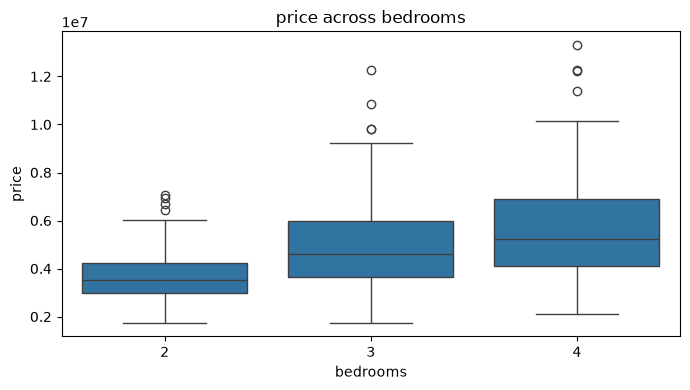

One-way ANOVA: F-stat = 46.6272, p-value = 2.2503e-19 -> Reject H0


In [6]:
# Select top bedroom groups (e.g. 2, 3, 4 bedrooms)
groups_used = df[anova_group_col].value_counts().head(3).index.tolist()
anova_df = df[df[anova_group_col].isin(groups_used)]
samples = [anova_df.loc[anova_df[anova_group_col] == g, anova_num_col].dropna() for g in groups_used]

print(anova_df.groupby(anova_group_col)[anova_num_col].agg(["count", "mean"]))

plt.figure(figsize=(7, 4))
sns.boxplot(data=anova_df, x=anova_group_col, y=anova_num_col)
plt.title(f"{anova_num_col} across {anova_group_col}")
plt.tight_layout()
plt.show()

f_stat, anova_p = f_oneway(*samples)
print(f"One-way ANOVA: F-stat = {f_stat:.4f}, p-value = {anova_p:.4e} -> {decide(anova_p)}")

In [7]:
clean_anova = anova_df[[anova_num_col, anova_group_col]].dropna()
tukey = pairwise_tukeyhsd(clean_anova[anova_num_col], clean_anova[anova_group_col], alpha=alpha)
print(tukey)

       Multiple Comparison of Means - Tukey HSD, FWER=0.05        
group1 group2   meandiff   p-adj     lower        upper     reject
------------------------------------------------------------------
     2      3 1322576.0745    0.0  906315.7687 1738836.3804   True
     2      4 2097735.8359    0.0 1559309.1594 2636162.5125   True
     3      4  775159.7614 0.0004  301105.6105 1249213.9123   True
------------------------------------------------------------------


In [8]:
results = pd.DataFrame({
    "Test": ["Welch's t-test", "Chi-square test", "One-way ANOVA"],
    "Statistic": [t_stat, chi2, f_stat],
    "p-value": [t_p, chi_p, anova_p]
})
results["Decision"] = results["p-value"].apply(decide)
print(results)
results.to_csv("hypothesis_testing_results.csv", index=False)

              Test  Statistic       p-value   Decision
0   Welch's t-test  11.853200  3.632669e-25  Reject H0
1  Chi-square test   5.423399  1.986865e-02  Reject H0
2    One-way ANOVA  46.627152  2.250253e-19  Reject H0
